<a href="https://colab.research.google.com/github/Dibyasis905/ML-Projects/blob/main/Water_Quality_Monitoring_and_Prediction_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Algorithm
1. Start
2. Data Generation
Generate synthetic water quality data using numpy and convert it into a DataFrame using pandas. Assign labels (Safe, Irrigation, Not Safe) based on predefined conditions for usability.
3. Label Encoding
Convert categorical labels into numerical form using LabelEncoder.
4. Data Splitting
Split the dataset into training and testing sets using train_test_split.
5. Model Training
Train the model using RandomForestClassifier, which is based on multiple decision trees.
6. Model Evaluation
Predict on test data and calculate accuracy to evaluate model performance.
7. Anomaly Detection
Apply the Isolation Forest algorithm to detect abnormal water quality samples. Mark data points as normal (1) or anomaly (-1) based on their deviation from normal patterns.
8. Data Visualization
Visualize the relationship between parameters (such as pH and Dissolved Oxygen) using scatter plots. Use color mapping to represent different water quality labels.
9. Geographical Mapping
Generate latitude and longitude values for each data point and plot them on an interactive map using Folium. Display water quality labels as popups on map markers.
10. Stop

In [ ]:
# step 2
import pandas as pd
import numpy as np

np.random.seed(42)
n=100

data={"pH": np.random.uniform(5.5,9,n),
      "Turbidity": np.random.uniform(1,10,n),
      "DO": np.random.uniform(3, 10, n), #dissolved oxygen
      "Heavy_Metals": np.random.uniform(0.0, 0.1, n),
      "Temperature": np.random.uniform(15, 35, n),
      "Rainfall": np.random.uniform(0, 50, n)
      }

df = pd.DataFrame(data)


In [ ]:

def classify(row):
    if (6.5 <= row["pH"] <= 8.5 and
        row["Turbidity"] < 5 and
        row["DO"] > 5 and
        row["Heavy_Metals"] < 0.03):
        return "Safe" # water is suitable for all chores
    elif row["Turbidity"] < 7:
        return "Irrigation" # indicating water is only for irrigation purposes and not daily uses
    else:
        return "Not Safe" # water is unsuitable for any task

df["Label"] = df.apply(classify, axis=1)

df.to_csv("water_quality.csv", index=False)

In [ ]:
df.head()

,pH,Turbidity,DO,Heavy_Metals,Temperature,Rainfall,Label
0,6.810890,1.282863,7.494222,0.005168,17.062477,34.908086,Safe
1,8.827500,6.727694,3.588980,0.053135,33.051058,26.804818,Irrigation
2,8.061979,3.829204,4.131401,0.054064,25.105047,15.476381,Irrigation
3,7.595305,5.577136,9.289879,0.063743,31.529149,40.689751,Irrigation
4,6.046065,9.168098,7.245003,0.072609,21.400992,34.236559,Not Safe


In [ ]:
# step 3,4,5,6
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# Encode labels
le = LabelEncoder()
df["Label"] = le.fit_transform(df["Label"])


X = df.drop("Label", axis=1)
y = df["Label"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = RandomForestClassifier()
model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))

Accuracy: 0.9


In [ ]:
df.head()

,pH,Turbidity,DO,Heavy_Metals,Temperature,Rainfall,Label
0,6.810890,1.282863,7.494222,0.005168,17.062477,34.908086,2
1,8.827500,6.727694,3.588980,0.053135,33.051058,26.804818,0
2,8.061979,3.829204,4.131401,0.054064,25.105047,15.476381,0
3,7.595305,5.577136,9.289879,0.063743,31.529149,40.689751,0
4,6.046065,9.168098,7.245003,0.072609,21.400992,34.236559,1


In [ ]:
# step 7
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.05)
df["Anomaly"] = iso.fit_predict(X)

In [ ]:
df.head()

,pH,Turbidity,DO,Heavy_Metals,Temperature,Rainfall,Label,Anomaly
0,6.810890,1.282863,7.494222,0.005168,17.062477,34.908086,2,1
1,8.827500,6.727694,3.588980,0.053135,33.051058,26.804818,0,1
2,8.061979,3.829204,4.131401,0.054064,25.105047,15.476381,0,1
3,7.595305,5.577136,9.289879,0.063743,31.529149,40.689751,0,1
4,6.046065,9.168098,7.245003,0.072609,21.400992,34.236559,1,1


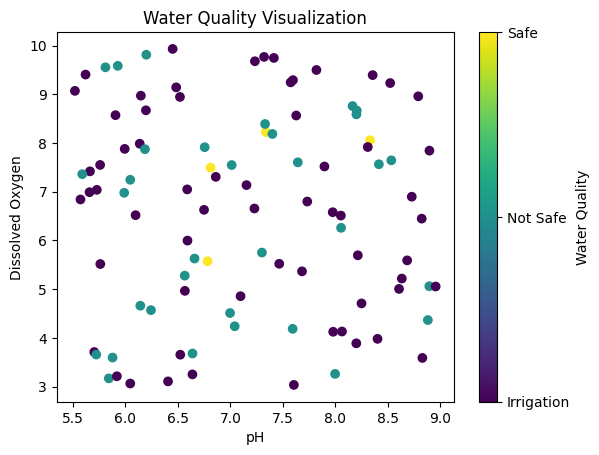

In [ ]:
# step 8
import matplotlib.pyplot as plt

scatter = plt.scatter(df["pH"], df["DO"], c=df["Label"], cmap="viridis")

plt.xlabel("pH")
plt.ylabel("Dissolved Oxygen")
plt.title("Water Quality Visualization")

cbar = plt.colorbar(scatter)
cbar.set_label("Water Quality")


cbar.set_ticks([0, 1, 2])
cbar.set_ticklabels(["Irrigation", "Not Safe", "Safe"])

plt.show()

In [ ]:
# step 9
df["Latitude"] = np.random.uniform(22.4, 22.7, len(df))
df["Longitude"] = np.random.uniform(88.2, 88.5, len(df))

import folium

m = folium.Map(location=[22.57, 88.36], zoom_start=10)

color_map = {0: "blue", 1: "red", 2: "green"}

for i in range(40):
    folium.Marker([df.iloc[i]["Latitude"], df.iloc[i]["Longitude"]],
        popup=str(df.iloc[i]["Label"]),
        icon=folium.Icon(color=color_map[df.iloc[i]["Label"]])).add_to(m)

m